# 9 · Continued Pretraining

Phase 1 in miniature: keep training SmolLM2-135M with its original objective (predict the next token) on nothing but
our verbalized baskets, then rerun section 8's test.

**Running on CPU with PyTorch, scaled down — read this before comparing with the course.**
On this CPU one training step takes ~10–12 s and scoring one test case ~13 s, so the course's run (800 steps, then
200 cases per model) would take many hours. To save time I made two reductions:

- **Training: 100 steps × 16 baskets = 1,600 baskets (~1.7% of one pass), vs the course's 800 steps / 12,800
  baskets / 13%.** Same batch size (16), peak learning rate (1e-4), warmup (50 steps) and cosine decay — the cosine
  is fitted to 100 steps so it still ends at a tenth of the peak. Held-out loss every 50 steps (course: every 100).
- **Test: the first 50 of section 8's 200 cases** (course: 200). *Every* method in this notebook — random,
  popularity, off-the-shelf, trained — is compared on those same 50 cases, so the comparison is like-for-like; the
  off-the-shelf scores are simply the first 50 rows of section 8's 200.

**The results are noisy because of these small sizes.** With 50 cases a single case moves the MRR by up to 0.02, so
the bootstrap ranges are wide, and the model saw an eighth as many baskets as the course's. Read gaps as rough.
Training and scoring ran as background jobs (`work/mybasket/jobs.py`); this notebook loads their saved results.

In [1]:
import json
import os
import time
import warnings
from pathlib import Path

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from thilimarketbasket.dataset import generate_dataset
from thilimarketbasket.evaluate import candidate_token_ids, make_cases, popularity_scores
from thilimarketbasket.pretrain import _encode
from thilimarketbasket.verbalize import verbalize_prefix
from mybasket.pretrain import pad, next_token_loss as reference_loss
from mybasket.score import load, score_candidates
from mybasket.probe import sample_baskets

torch.set_num_threads(20)
data = generate_dataset(n_baskets=100_000, seed=0)
names = [item.name for item in data.catalog]
position = {name: i for i, name in enumerate(names)}

is_val = np.random.default_rng(0).random(len(data.baskets)) < 0.05      # the split from section 7
train = [b for b, v in zip(data.baskets, is_val) if not v]
val = [b for b, v in zip(data.baskets, is_val) if v]
print(f"{len(train):,} training baskets, {len(val):,} held out")

95,002 training baskets, 4,998 held out


## The loss

At every position the model gives 49,152 scores (one per vocabulary token); the loss is −log(probability of the token
that really came next), averaged over real tokens. Blind guessing = log(49,152) = 10.8.

Two details: **padding** (fill short rows with id 0) is dropped from the loss with a **mask**; and **inputs/targets
are shifted by one** (position t predicts token t+1), the mask shifted the same way.

In [2]:
def my_next_token_loss(model, ids, mask):
    """Average cross-entropy of predicting each token from the ones before it, ignoring padding."""
    logits = model(input_ids=ids[:, :-1]).logits.float()                # a score for every vocabulary token, at each position
    per_token = torch.nn.functional.cross_entropy(logits.transpose(1, 2), ids[:, 1:], reduction="none")
    real = mask[:, 1:]                                                   # 1 where the target is a real token
    return (per_token * real).sum() / real.sum()


model, tokenizer = load("HuggingFaceTB/SmolLM2-135M")

examples = _encode(tokenizer, train[:16], np.arange(16))
ids, mask = pad(examples)
print("a batch of 16 baskets:", tuple(ids.shape), "(the width is the longest basket, rounded up to a multiple of 16)")
print("padding in the batch:", f"{1 - float(mask.mean()):.0%}")
print()
with torch.no_grad():
    mine = float(my_next_token_loss(model, ids, mask))
    ref = float(reference_loss(model, ids, mask))
    labels = ids.clone(); labels[mask == 0] = -100                        # Hugging Face's own loss, as an independent check
    hf = float(model(input_ids=ids, labels=labels).loss)
print(f"my loss:                      {mine:.4f}")
print(f"reference loss (mybasket):    {ref:.4f}")
print(f"Hugging Face built-in loss:   {hf:.4f}")
print(f"if it guessed uniformly over its {len(tokenizer):,} tokens: {np.log(len(tokenizer)):.2f}")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  40%|███▉      | 108/272 [00:00<00:00, 1025.89it/s]

Loading weights:  84%|████████▍ | 228/272 [00:00<00:00, 1125.95it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1137.87it/s]

a batch of 16 baskets: (16, 224) (the width is the longest basket, rounded up to a multiple of 16)
padding in the batch: 51%



my loss:                      3.5878
reference loss (mybasket):    3.5878
Hugging Face built-in loss:   3.5879
if it guessed uniformly over its 49,152 tokens: 10.80


(The course's reference `next_token_loss` is MLX-only, so I check against my PyTorch port and against Hugging Face's
built-in causal-LM loss with padding labelled −100.)

## One batch, five steps (course: twenty)

AdamW (lr 1e-4, weight decay 0.01), gradients clipped at 1.0, float32. The loss on that batch must fall.
(The batch of 16 is run as two halves with gradient accumulation — same gradient, half the memory — because a
full batch of 16 ran out of Docker's memory on this machine.)

In [3]:
trainee, _ = load("HuggingFaceTB/SmolLM2-135M")
trainee.train()
optimizer = torch.optim.AdamW(trainee.parameters(), lr=1e-4, weight_decay=0.01)

def accumulated_step(model, examples, parts=2):
    """One update on the whole batch, run in `parts` pieces to fit Docker's memory. Each piece's loss is weighted by
    its share of the real tokens, so the summed gradient (and the loss) equal the one-batch values exactly."""
    total = float(pad(examples)[1][:, 1:].sum())
    size = -(-len(examples) // parts)
    loss_value = 0.0
    for start in range(0, len(examples), size):
        p_ids, p_mask = pad(examples[start:start + size])
        weight = float(p_mask[:, 1:].sum()) / total
        loss = my_next_token_loss(model, p_ids, p_mask) * weight
        loss.backward()
        loss_value += loss.item()
    return loss_value

DEMO_STEPS = 5                     # course: 20 (cut to 5 to save time: each step is ~25 s on this CPU)
for step in range(DEMO_STEPS):
    loss = accumulated_step(trainee, examples)
    torch.nn.utils.clip_grad_norm_(trainee.parameters(), 1.0)   # cap the size of an update
    optimizer.step()
    optimizer.zero_grad(set_to_none=True)
    print(f"step {step:>2}  loss on this batch {loss:.3f}")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  50%|█████     | 137/272 [00:00<00:00, 1367.88it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1333.15it/s]

step  0  loss on this batch 3.588


step  1  loss on this batch 2.854


step  2  loss on this batch 2.336


step  3  loss on this batch 1.956


step  4  loss on this batch 1.652


That's memorising 16 baskets. The fair check is a batch it hasn't trained on:

In [4]:
fresh_ids, fresh_mask = pad(_encode(tokenizer, train[1000:1016], np.arange(16)))
trainee.eval()
with torch.no_grad():
    print(f"fresh batch: before {float(my_next_token_loss(model, fresh_ids, fresh_mask)):.3f}   "
          f"after {DEMO_STEPS} steps on another batch {float(my_next_token_loss(trainee, fresh_ids, fresh_mask)):.3f}")
del trainee, optimizer

fresh batch: before 3.486   after 5 steps on another batch 1.838


## The run (background job, reduced to 100 steps)

`mybasket.pretrain.pretrain` = the reference loop in PyTorch: length-bucketed batches, a fresh shuffle each time a
basket is drawn, warmup 50 then cosine to a tenth, held-out loss on 300 baskets every 100 steps, resumable.

In [5]:
STEPS, BATCH = 100, 16                    # course: 800 x 16 (reduced to save time; see the note at the top)
CHECKPOINT = Path("checkpoints") / f"baskets-{STEPS}x{BATCH}"
print(f"{STEPS * BATCH:,} baskets, about {STEPS * BATCH * 108 / 1e6:.1f} million tokens: "
      f"{STEPS * BATCH / len(train):.0%} of one pass over the training data")

1,600 baskets, about 0.2 million tokens: 2% of one pass over the training data


In [6]:
if not (CHECKPOINT / "model.safetensors").exists():
    from mybasket.pretrain import pretrain     # ~20 min on this CPU; normally run with: python -m mybasket.jobs train --steps 100
    pretrain("HuggingFaceTB/SmolLM2-135M", train, str(CHECKPOINT), val_baskets=val[:300], steps=STEPS, batch_size=BATCH,
             eval_every=50)
else:
    print("a checkpoint is already there (trained by the background job), so we reuse it.")
history = json.loads((CHECKPOINT / "history.json").read_text())
print(f"training took {history[-1]['seconds'] / 60:.0f} minutes, {history[-1]['tokens'] / history[-1]['seconds']:.0f} tokens/s")

a checkpoint is already there (trained by the background job), so we reuse it.
training took 20 minutes, 145 tokens/s


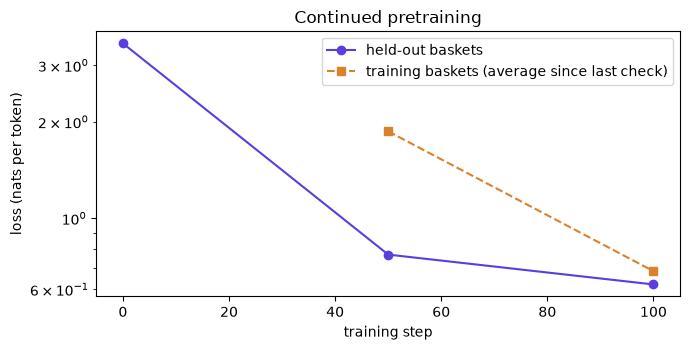

,step,val_loss,tokens,seconds
0,0,3.509,0,0.000
1,50,0.770,87931,784.131
2,100,0.621,176494,1217.017


In [7]:
curve = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(curve["step"], curve["val_loss"], "o-", color="#5b3de0", label="held-out baskets")
ax.plot(curve["step"][1:], curve["loss"][1:], "s--", color="#d9822b", label="training baskets (average since last check)")
ax.set_xlabel("training step")
ax.set_ylabel("loss (nats per token)")
ax.set_yscale("log")
ax.legend()
ax.set_title("Continued pretraining")
plt.tight_layout()
plt.show()
curve[["step", "val_loss", "tokens", "seconds"]].round(3)

## Does it write baskets?

30 baskets sampled from "Basket:" at temperature 1.0 (my PyTorch port of the reference sampler).

In [8]:
tuned, tuned_tokenizer = load(str(CHECKPOINT))
_, stats = sample_baskets(tuned, tuned_tokenizer, names, n=30, batch=30, seed=0, log=lambda m: None, return_raw=True)
written = stats["raw"]                      # the items exactly as the model wrote them, before any cleaning
for basket in written[:3]:
    print(basket, "\n")

items = [i for b in written for i in b]
print(f"{len(items)} items written in {len(written)} baskets")
print(f"names that are in the catalogue:       {np.mean([i in position for i in items]):.0%}")
print(f"baskets that repeat an item:           {np.mean([len(set(b)) < len(b) for b in written]):.0%}")
print(f"mean items per basket:                 {np.mean([len(b) for b in written]):.1f}  (the real data: 8.0)")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3573.60it/s]

['Masala Mantra Garam Masala sachet 10 g', 'Poha 1 kg', 'Surya Grains Salt 1 kg', 'Cauliflower 1 kg', 'Garlic 1 kg', 'Surya Grains Vermicelli 500 g'] 

['Crunch Club Namkeen Mixture Rs 5 pack', 'Golden Drop Sunflower Oil 500 ml', 'Gram Doula Garbage Bags Rs 10 pack', 'Shuddh Agarbatti (Incense) pack of 20', 'Tomato 1 kg', 'Nandini Pure Paneer 500 g', 'Sparkle Home Detergent Powder 1 kg', 'Glow Garden Toothpaste 100 g', 'Kaveri Valley Jaggery 1 kg', 'Swad Sagar Mustard Seeds sachet 10 g', 'Garlic 500 g', 'Crunchy Crust Glucose Biscuits 100 g', 'Ginger 500 g', 'Masala Mantra Red Taplear Sake Sachet strip of 10', 'Garlic 1 kg', 'Ruchira Groundnut Oil 1 L', 'Gokul Fresh Milk 500 ml'] 

['Okra (Bhindi) 1 kg', 'Surya Grains Salt 1 kg', 'Vivat Coffee Powder 200 g', "Baker's Basket Bread 400 g", 'Tomato 1 kg', 'Nandini Pure Milk 500 ml', 'Gokul Fresh Butter 500 g', 'Surya Grains Vermicelli 200 g'] 

232 items written in 30 baskets
names that are in the catalogue:       78%
baskets that repeat 

## The same test as section 8

Scores for the off-the-shelf and trained models were computed by background jobs with exactly the code below
(`verbalize_prefix(case['visible'], seed=k)` → `score_candidates`), and are loaded here.

In [9]:
N_CASES = 50                                                   # course: 200 (reduced to save time; see the note at the top)
cases = make_cases(val, names, n_cases=200, seed=0)[:N_CASES]  # the first 50 of section 8's 200 cases
candidates = candidate_token_ids(tokenizer, names)

def my_rank_of(scores, target, exclude=()):
    keep = np.ones(len(scores), dtype=bool)
    keep[list(exclude)] = False
    keep[target] = False
    return 1 + int((scores[keep] >= scores[target]).sum())

def run_cases(m, tok, cache_dir):
    """Saved scores from the background job (first N_CASES rows), else score live."""
    for saved in (Path(cache_dir) / f"scores-{N_CASES}.npy", Path(cache_dir) / "scores-200.npy"):
        if saved.exists():
            return list(np.load(saved)[:N_CASES])
    return [score_candidates(m, tok.encode(verbalize_prefix(c["visible"], seed=k)), candidates) for k, c in enumerate(cases)]

def ranks_for(score_list):
    return [my_rank_of(s, position[c["target"]], [position[v] for v in c["visible"]]) for s, c in zip(score_list, cases)]

def summary(ranks):
    r = np.asarray(ranks)
    return {"MRR": np.mean(1 / r), "hits@1": np.mean(r <= 1), "hits@10": np.mean(r <= 10),
            "hits@50": np.mean(r <= 50), "median rank": np.median(r)}

base_ranks = ranks_for(run_cases(model, tokenizer, "checkpoints/smollm2-base"))
print(f"off-the-shelf MRR on these {N_CASES} cases:", round(float(np.mean(1 / np.asarray(base_ranks))), 3),
      "(section 8's figure was over all 200)")

off-the-shelf MRR on these 50 cases: 0.01 (section 8's figure was over all 200)


In [10]:
tuned_scores = run_cases(tuned, tuned_tokenizer, CHECKPOINT)
check = score_candidates(tuned, tuned_tokenizer.encode(verbalize_prefix(cases[0]["visible"], seed=0)), candidates)
print("saved trained scores reproduce live for case 0:", np.allclose(tuned_scores[0], check, atol=1e-4))
tuned_ranks = ranks_for(tuned_scores)

pop = popularity_scores(train, names)
pop_ranks = ranks_for([pop] * len(cases))
rows = {"random": {"MRR": np.mean(1 / np.arange(1, len(names) + 1))},
        "popularity": summary(pop_ranks), "off-the-shelf model": summary(base_ranks),
        "trained model": summary(tuned_ranks)}
pd.DataFrame(rows).T.round(3)

saved trained scores reproduce live for case 0: True


,MRR,hits@1,hits@10,hits@50,median rank
random,0.007,NaN,NaN,NaN,NaN
popularity,0.042,0.00,0.12,0.38,132.0
off-the-shelf model,0.010,0.00,0.00,0.16,279.5
trained model,0.080,0.04,0.16,0.42,77.5


## Ranges, and case-by-case gaps (bootstrap)

In [11]:
def interval(values, draws=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)
    means = [rng.choice(values, size=len(values)).mean() for _ in range(draws)]
    return np.percentile(means, [2.5, 97.5])

reciprocal = {k: 1 / np.asarray(r) for k, r in (("popularity", pop_ranks), ("off-the-shelf", base_ranks), ("trained", tuned_ranks))}
for label, values in reciprocal.items():
    low, high = interval(values)
    print(f"{label:14} MRR {values.mean():.3f}   (95% range {low:.3f} to {high:.3f})")

gain = reciprocal["trained"] - reciprocal["popularity"]
low, high = interval(gain)
print(f"\ntrained minus popularity, case by case: {gain.mean():+.3f}   (95% range {low:+.3f} to {high:+.3f})")
gain = reciprocal["trained"] - reciprocal["off-the-shelf"]
low, high = interval(gain)
print(f"trained minus off-the-shelf:            {gain.mean():+.3f}   (95% range {low:+.3f} to {high:+.3f})")

popularity     MRR 0.042   (95% range 0.022 to 0.069)
off-the-shelf  MRR 0.010   (95% range 0.006 to 0.015)
trained        MRR 0.080   (95% range 0.034 to 0.142)

trained minus popularity, case by case: +0.037   (95% range -0.003 to +0.089)
trained minus off-the-shelf:            +0.070   (95% range +0.026 to +0.130)


## Is it the basket doing it?

In [12]:
blank_file = CHECKPOINT / "scores-blank.npy"
blank = np.load(blank_file) if blank_file.exists() else score_candidates(tuned, tuned_tokenizer.encode("Basket:"), candidates)
blank_ranks = ranks_for([blank] * len(cases))
print("trained model, scores with the basket:    MRR", f"{np.mean(1 / np.asarray(tuned_ranks)):.3f}")
print("trained model, scores with NO basket:     MRR", f"{np.mean(1 / np.asarray(blank_ranks)):.3f}")

trained model, scores with the basket:    MRR 0.080
trained model, scores with NO basket:     MRR 0.068


## Where does the gain come from?

A case "completes a planted set" if the hidden item belongs to a planted itemset and all the set's other items are
visible — the one situation where the basket tells you something popularity can't.

In [13]:
planted_sets = [set(p.items) for p in data.planted]

def completes_a_planted_set(case):
    everything = set(case["visible"]) | {case["target"]}
    return any(case["target"] in s and s <= everything for s in planted_sets)

completes = np.array([completes_a_planted_set(c) for c in cases])
split = {}
for label, chosen in (("hidden item completes a planted set", completes), ("it does not", ~completes)):
    split[label] = {"cases": int(chosen.sum()),
                    "popularity": np.mean(1 / np.asarray(pop_ranks)[chosen]),
                    "off-the-shelf": np.mean(1 / np.asarray(base_ranks)[chosen]),
                    "trained": np.mean(1 / np.asarray(tuned_ranks)[chosen]),
                    "trained hits@10": np.mean(np.asarray(tuned_ranks)[chosen] <= 10)}
pd.DataFrame(split).T.round(3)

,cases,popularity,off-the-shelf,trained,trained hits@10
hidden item completes a planted set,12.0,0.130,0.015,0.249,0.417
it does not,38.0,0.015,0.008,0.026,0.079


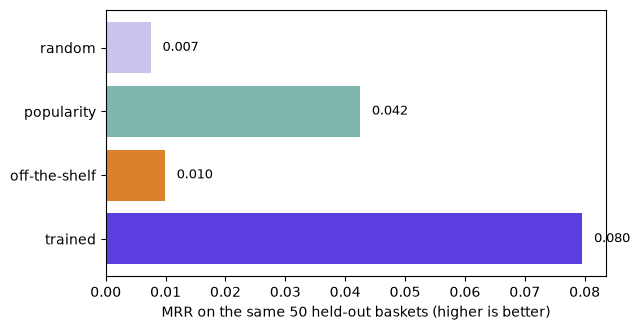

In [14]:
labels = ["random", "popularity", "off-the-shelf", "trained"]
values = [rows["random"]["MRR"], rows["popularity"]["MRR"], rows["off-the-shelf model"]["MRR"], rows["trained model"]["MRR"]]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(labels, values, color=["#c9c3ee", "#7fb7ae", "#d9822b", "#5b3de0"])
ax.invert_yaxis()
ax.set_xlabel(f"MRR on the same {N_CASES} held-out baskets (higher is better)")
for i, v in enumerate(values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## What I changed from the course (no Mac), and every reduction

- **Training code:** `work/mybasket/pretrain.py`, a PyTorch port of the MLX `pretrain` (same bucketing, shuffling,
  AdamW, clipping, warmup + cosine, float32), with batches planned up front from the seed and a resumable save every
  50 steps. Changes vs the course's untested PyTorch appendix: length bucketing like the reference (the appendix drew
  random baskets), `dtype=` instead of `torch_dtype=`, and **gradient accumulation** — each batch of 16 runs as two
  halves of 8, weighted by token count so the gradient is identical — because a full batch ran out of Docker's
  ~11.5 GB memory (the first 100-step run was killed at step ~15). Checked: the losses at steps 10 and 20 match the
  full-batch run exactly (3.499, 2.404).
- **Reduction — training:** 100 steps × 16 (course 800 × 16), to save time. Schedule fitted to 100 steps.
- **Reduction — test:** the first 50 of the 200 cases (course 200), the same 50 for every row.
- **Reduction — demo:** the "one batch" demo runs 5 steps (course 20).
- **The numbers are noisy** because of these small sizes; a single case moves the MRR by up to 0.02.
- Loss check: the course's reference loss is MLX-only, so mine is checked against my PyTorch port and against
  Hugging Face's built-in loss.

## Test yourself

**1. Why does the loss drop so fast in the first 50–100 steps and then slowly?**
The first steps teach the format and vocabulary: that a basket starts with "Basket:", that items are separated by
semicolons, and which item names exist. That's most of the predictable text. What's left — which items go with which
— is a much smaller part of the loss and is learned slowly.

**2. Why compare the trained model with popularity, not just with the off-the-shelf model?**
The off-the-shelf model has never seen our shop, so beating it is easy and says little. Popularity is the simplest
thing that actually works; a trained model is only useful if it beats "suggest what everyone buys".

**3. Why split the cases into "completes a planted set" and the rest?**
One average can hide where the gain comes from. If the model is much better only when the visible items are all but
one of a planted set, it has learned those planted patterns; if it's better everywhere, it learned something broader.

## My notes

Training on just 1,600 baskets already lifted the model from MRR 0.010 to 0.080 on the same 50 cases, almost all of it on baskets that complete a planted set (0.249 vs 0.130 for popularity). Surprising: with only 50 cases the gain over popularity isn't clearly real (its 95% range touches zero), and the model still wrote made-up names 22% of the time.